<div style="background-color:#DFC7F2; padding:15px; margin:15px;">


**Центр непрерывного образования НИУ ВШЭ**

## Программа «Python для автоматизации и анализа данных»

### Рекурсия в Python

</div>

## Что такое рекурсия?

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

**Рекурсия** — это приём программирования, при котором функция вызывает **саму себя**.

Любая рекурсивная функция состоит из двух частей:
* **Базовый случай (base case)** — условие, при котором функция прекращает вызывать себя и возвращает конкретное значение. Без него рекурсия будет бесконечной.
* **Рекурсивный случай (recursive case)** — вызов функцией самой себя с изменёнными аргументами, приближающими к базовому случаю.
</div>

In [6]:
def countdown(n):
    """Обратный отсчёт"""
    if n <= 0:          # базовый случай
        print("Пуск!")
    else:               # рекурсивный случай
        print(n)
        countdown(n - 1)

countdown(5)

5
4
3
2
1
Пуск!


## Классика №1: факториал

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Факториал числа `n` (обозначается `n!`) — это произведение всех натуральных чисел от 1 до n:

`5! = 5 × 4 × 3 × 2 × 1 = 120`

По определению: `0! = 1`

Рекурсивная формула: `n! = n × (n-1)!`
</div>

### Итеративное решение (цикл)

In [7]:
def factorial_iter(n):
    result = 1
    for i in range(2, n + 1):
        result *= i
    return result

print(factorial_iter(5))  # 120

120


### Рекурсивное решение

In [8]:
def factorial(n):
    if n == 0:          # базовый случай
        return 1
    return n * factorial(n - 1)  # рекурсивный случай

print(factorial(5))   # 120
print(factorial(0))   # 1
print(factorial(10))  # 3628800

120
1
3628800


### Как это работает?

Разберём вызов `factorial(4)` пошагово:

```
factorial(4)
  → 4 * factorial(3)
          → 3 * factorial(2)
                  → 2 * factorial(1)
                          → 1 * factorial(0)
                                  → 1          ← базовый случай
                          → 1 * 1 = 1
                  → 2 * 1 = 2
          → 3 * 2 = 6
  → 4 * 6 = 24
```

Каждый вызов «откладывается» в **стек вызовов** (call stack), пока не будет достигнут базовый случай. Потом результаты «сворачиваются» обратно.

## Классика №2: числа Фибоначчи

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Последовательность Фибоначчи: `0, 1, 1, 2, 3, 5, 8, 13, 21, ...`

Каждое число — сумма двух предыдущих:

`F(0) = 0, F(1) = 1, F(n) = F(n-1) + F(n-2)`
</div>

### Наивная рекурсия

In [9]:
def fib(n):
    if n <= 1:       # два базовых случая
        return n
    return fib(n - 1) + fib(n - 2)

print([fib(i) for i in range(10)])  # [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34]


### Проблема: экспоненциальная сложность

Наивная рекурсия **ужасно медленная** для больших `n`, потому что одни и те же значения пересчитываются многократно:

```
fib(5)
├── fib(4)
│   ├── fib(3)
│   │   ├── fib(2)      ← считается
│   │   └── fib(1)
│   └── fib(2)          ← считается ПОВТОРНО
└── fib(3)              ← считается ПОВТОРНО
    ├── fib(2)          ← и ещё раз...
    └── fib(1)
```

Убедимся в этом, замерив время:

In [10]:
import time

for n in [20, 30, 35]:
    start = time.time()
    result = fib(n)
    elapsed = time.time() - start
    print(f"fib({n}) = {result}, время: {elapsed:.3f} сек.")

fib(20) = 6765, время: 0.001 сек.
fib(30) = 832040, время: 0.062 сек.
fib(35) = 9227465, время: 0.552 сек.


## Проблема глубины рекурсии

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Python ограничивает глубину рекурсии (по умолчанию ~1000 вызовов). При превышении — <code style="color:red;background:none">RecursionError</code>.

Это сделано специально, чтобы бесконечная рекурсия не «съела» всю память.
</div>

In [11]:
import sys
print(f"Лимит рекурсии: {sys.getrecursionlimit()}")

Лимит рекурсии: 3000


In [12]:
# Попробуем вычислить факториал большого числа — упадёт с ошибкой
try:
    factorial(5000)
except RecursionError as e:
    print(f"Ошибка! {e}")

Ошибка! maximum recursion depth exceeded


Можно увеличить лимит вручную, но это **плохое решение** — оно лишь отодвигает проблему и рискует вызвать настоящий переполнение стека (segfault):

```python
sys.setrecursionlimit(10000)  # НЕ рекомендуется!
```

Вместо этого используем **декораторы** для элегантного решения проблем рекурсии.

## Решение 1: мемоизация (кэширование)

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

**Мемоизация** — это сохранение уже вычисленных результатов, чтобы не считать одно и то же дважды.

Это решает проблему **скорости** (для Фибоначчи — из экспоненциальной сложности в линейную).
</div>

### Пишем декоратор мемоизации вручную

In [13]:
from functools import wraps

def memoize(func):
    """Декоратор: кэширует результаты вызовов функции"""
    cache = {}
    @wraps(func)
    def wrapper(*args):
        if args not in cache:
            cache[args] = func(*args)
        return cache[args]
    return wrapper

@memoize
def fib_memo(n):
    if n <= 1:
        return n
    return fib_memo(n - 1) + fib_memo(n - 2)

# Теперь быстро!
start = time.time()
print(fib_memo(100))  # 354224848179261915075
print(f"Время: {time.time() - start:.5f} сек.")

354224848179261915075
Время: 0.00014 сек.


### Готовый декоратор: <code style="color:red;background:none">functools.lru_cache</code>

Python уже включает встроенный декоратор меморизации — <code style="color:red;background:none">lru_cache</code>. Не нужно писать свой:

In [ ]:
from functools import lru_cache

@lru_cache(maxsize=None)  # maxsize=None — кэш без ограничения размера
def fib_cached(n):
    if n <= 1:
        return n
    return fib_cached(n - 1) + fib_cached(n - 2)

start = time.time()
print(fib_cached(300))
print(f"Время: {time.time() - start:.5f} сек.")

# Можно посмотреть статистику кэша:
print(fib_cached.cache_info())

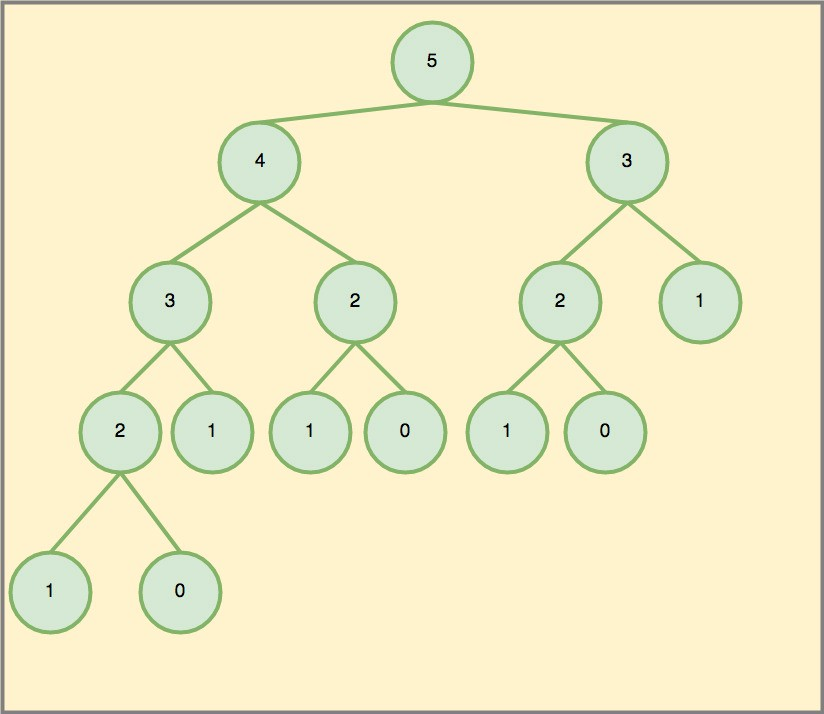

### Сравним скорость: без кэша vs с кэшем

In [ ]:
import time

# Без меморизации
start = time.time()
fib(35)
print(f"Без кэша  fib(35): {time.time() - start:.3f} сек.")

# С меморизацией
start = time.time()
fib_cached(35)
print(f"С кэшем   fib(35): {time.time() - start:.6f} сек.")

## Решение 2: декоратор хвостовой рекурсии

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

**Хвостовая рекурсия (tail recursion)** — это форма рекурсии, где рекурсивный вызов — **последняя** операция в функции (после него ничего не вычисляется).

Python **не оптимизирует** хвостовую рекурсию автоматически (в отличие от некоторых других языков). Но мы можем написать декоратор, который превращает хвостовую рекурсию в **цикл** — и тем самым обходит лимит глубины!
</div>

### Обычная рекурсия vs хвостовая

Сравним два варианта факториала:

In [1]:
# Обычная рекурсия — после вызова ещё нужно умножить
def factorial_normal(n):
    if n == 0:
        return 1
    return n * factorial_normal(n - 1)  # ← n * ... — операция ПОСЛЕ вызова

# Хвостовая рекурсия — вызов последний, результат копится в аккумуляторе
def factorial_tail(n, acc=1):
    if n == 0:
        return acc
    return factorial_tail(n - 1, n * acc)  # ← вызов — последняя операция

print(factorial_normal(5))  # 120
print(factorial_tail(5))    # 120

120
120


### Декоратор для оптимизации хвостовой рекурсии

Идея: вместо настоящего рекурсивного вызова — бросаем специальное исключение с аргументами, а в цикле ловим его и вызываем заново. Стек при этом **не растёт**.

In [ ]:
class TailCall(Exception):
    """Специальное исключение для передачи аргументов хвостового вызова"""
    def __init__(self, *args, **kwargs):
        self.args = args
        self.kwargs = kwargs

def tail_recursive(func):
    """Декоратор: превращает хвостовую рекурсию в цикл"""
    @wraps(func)
    def wrapper(*args, **kwargs):
        while True:
            try:
                result = func(*args, **kwargs)
                return result
            except TailCall as tc:
                args = tc.args
                kwargs = tc.kwargs
    
    # Заменяем рекурсивный вызов на выброс исключения
    wrapper.call = lambda *args, **kwargs: (_ for _ in ()).throw(TailCall(*args, **kwargs))
    return wrapper

In [ ]:
sys.set_int_max_str_digits(0)
@tail_recursive
def factorial_safe(n, acc=1):
    if n == 0:
        return acc
    raise TailCall(n - 1, n * acc)

# Работает даже для огромных чисел!
result = factorial_safe(5000)
print(f"factorial(5000) имеет {len(str(result))} цифр")
print(f"Первые 50 цифр: {str(result)[:50]}...")

factorial(5000) имеет 16326 цифр
Первые 50 цифр: 42285779266055435222010642002335844053907866746266...


Без декоратора `factorial(5000)` падал с <code style="color:red;background:none">RecursionError</code>. С декоратором — работает мгновенно и без ограничений по глубине!

## Решение 3: просто используйте цикл

<div style="background-color: rgba(220,255,5,1.00); padding: 15px; margin: 15px; border-radius: 8px; border-left: 5px solid rgba(220,255,5,1.00);color:black; width:80%">

Честный совет: если задача легко решается циклом — **используйте цикл**. Рекурсия хороша для задач с рекурсивной **структурой** (деревья, графы, вложенные данные), но для линейных вычислений цикл проще, быстрее и не имеет ограничений по глубине.
</div>

In [ ]:
def fib_iter(n):
    """Итеративный Фибоначчи — O(n) по времени, O(1) по памяти"""
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

start = time.time()
print(fib_iter(1000))
print(f"Время: {time.time() - start:.6f} сек.")

## Ещё примеры рекурсии

### Сумма цифр числа

In [ ]:
def digit_sum(n):
    """Рекурсивная сумма цифр числа"""
    n = abs(n)
    if n < 10:
        return n
    return n % 10 + digit_sum(n // 10)

print(digit_sum(12345))  # 1+2+3+4+5 = 15
print(digit_sum(999))    # 27

### Разворот списка

In [ ]:
def reverse_list(lst):
    """Рекурсивный разворот списка"""
    if len(lst) <= 1:
        return lst
    return [lst[-1]] + reverse_list(lst[:-1])

print(reverse_list([1, 2, 3, 4, 5]))  # [5, 4, 3, 2, 1]

### Возведение в степень

In [ ]:
@lru_cache  # не забываем про кэширование, если возможно
def power(base, exp):
    """Быстрое возведение в степень (рекурсивно)"""
    if exp == 0:
        return 1
    if exp % 2 == 0:
        half = power(base, exp // 2)
        return half * half
    return base * power(base, exp - 1)

print(power(2, 10))   # 1024
print(power(3, 5))    # 243

## Итого: когда что использовать

| Проблема | Решение | Инструмент |
|----------|---------|------------|
| Повторные вычисления (Фибоначчи) | Мемоизация | `@lru_cache` или свой `@memoize` |
| Глубина рекурсии > 1000 | Хвостовая рекурсия + декоратор | `@tail_recursive` |
| Линейная задача | Переписать на цикл | `for` / `while` |
| Древовидная структура | Рекурсия + кэш | `@lru_cache` |

## Потренируемся!

**№1.** Напишите рекурсивную функцию <code style="color:red;background:none">power(base, exp)</code>, которая возводит число `base` в степень `exp` (целую неотрицательную). Не используйте оператор `**`.

```python
print(power(2, 10))  # 1024
print(power(5, 0))   # 1
```

In [24]:

def power(base, exp):
    if exp == 0:
        return 1
    return base * power(base, exp - 1)

def better_power(base, exp):
    if exp == 0:
        return 1
    if exp % 2==0:
        half = better_power(base, exp//2)
        return half * half
    
    return  base * better_power(base, exp-1)
better_power(2,12)

4096

**№2.** Напишите рекурсивную функцию <code style="color:red;background:none">is_palindrome(s)</code>, которая проверяет, является ли строка палиндромом.

```python
print(is_palindrome("radar"))  # True
print(is_palindrome("hello"))  # False
```

In [ ]:
def is_pakindrome(s):
    if len(s) == 0:
        return True

    return False if s[0]!= s[-1] else is_pakindrome(s[1:-1])


False

In [ ]:
def power(base,exp):
    if exp == 0:
        return 1
    if exp%2==0:
        half= power(base, exp//2)
        return half * half
    return base*power(base, exp - 1)

**№3.** Напишите рекурсивную функцию <code style="color:red;background:none">flatten(lst)</code>, которая принимает вложенный список любой глубины и возвращает плоский список.

```python
print(flatten([1, [2, [3, 4], 5], [6]]))  # [1, 2, 3, 4, 5, 6]
```

In [ ]:

def flatten(data):
    result = []
    for item in result:
        if isinstance(item, list):
            result.extend(flatten(item))
        else:
            result.append(item)
    return result

**№4.** Возьмите свою функцию Фибоначчи и оберните её в <code style="color:red;background:none">@lru_cache</code>. Убедитесь, что `fib(500)` вычисляется мгновенно. Выведите `cache_info()` - это метод который добавляет докоратор lru_cache.


In [36]:
from functools import lru_cache
@lru_cache(maxsize=None)
def fib(n):
    if n <= 1:
        return n
    return fib(n-1) + fib(n-2)

print(fib(500))
print(fib.cache_info())


139423224561697880139724382870407283950070256587697307264108962948325571622863290691557658876222521294125
CacheInfo(hits=498, misses=501, maxsize=None, currsize=501)


**№5.** Напишите рекурсивную функцию <code style="color:red;background:none">gcd(a, b)</code>, которая находит наибольший общий делитель двух чисел по алгоритму Евклида.

```python
print(gcd(48, 18))   # 6
print(gcd(100, 75))  # 25
```

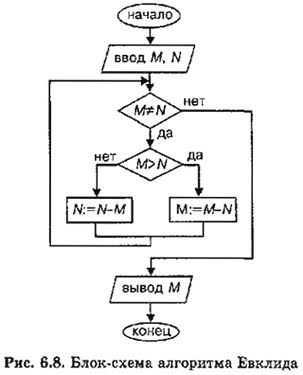
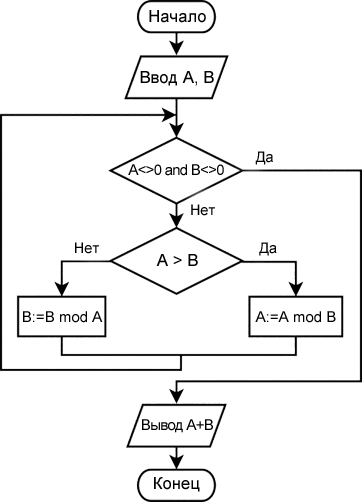

In [39]:
def gcd(a, b):
    if a == b:
        return a
    if a > b:
        return gcd(a - b, b)
    else:
        return gcd(a, b - a) 

gcd(100,75)

25